# Assignment 2A — PGD evasion and adversarial training

**Meet Fashion-MNIST.** Fashion-MNIST is a dataset of small product images from Zalando. Each image shows one item of clothing, footwear, or a bag. The classification task is to predict which of **ten categories** the item belongs to.

The dataset contains **70,000 grayscale images**, each **28 × 28 pixels**: 60,000 official training examples and 10,000 test examples. Each image has an integer label from **0 to 9** identifying its category.

The gallery below shows three training examples from each category, with its numeric label and name. Notice the variation within a class and similarities between classes such as T-shirt/top, pullover, coat, and shirt. These similarities help explain why some classification errors are more common than others.

[Dataset source and label definitions](https://github.com/zalandoresearch/fashion-mnist).

Use Fashion-MNIST to train a small clothing classifier and attack it, then improve the classifier by training on clean and adversarial examples. We will apply **PGD (Projected Gradient Descent)**, an attack that repeatedly changes image pixels to make the model misclassify them, projecting each update back within a chosen perturbation budget. The model architecture, reference training procedure, and an editable attack demonstration are provided. Complete the four **YOUR WORK** cells.

| Section | Task | Points |
|---|---|---:|
| 1.1 | Generate PGD attacks using one configuration | 30 |
| 1.2 | Measure accuracy drop, class results, and confusion matrices | 20 |
| 2.1 | Build additional training data and retrain the classifier | 30 |
| 2.2 | Evaluate the defense on the same Part 1 attacks | 20 |
| **Total** | | **100** |

**Submit:** `assignment_2a.ipynb` with your completed code, executed outputs, and figures. You may add cells if needed. Run provided setup and display cells unchanged; the API demonstration is explicitly editable. All experiment code is visible here; no hidden model or helper implementation.


In [ ]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "4")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "2")
from pathlib import Path
import json, platform, time
import numpy as np
import tensorflow as tf
import keras
from keras import layers
from keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 302
ATTACK_DROP_TARGET_PP = 75.0
DEFENSE_DROP_TARGET_PP = 10.0
CLEAN_FLOOR = 0.85
MAX_DROP_PP = 5.0
OUTPUT = Path("outputs")
OUTPUT.mkdir(exist_ok=True)
REFERENCE_CACHE = OUTPUT / "fashion_mnist_reference_60k.keras"
REFERENCE_HISTORY_CACHE = OUTPUT / "reference_training_history_60k.json"
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print({"python": platform.python_version(), "tensorflow": tf.__version__,
       "keras": keras.__version__, "numpy": np.__version__})


## Setup: load the dataset

Use all 60,000 official training images for training. Split the 10,000 official test images into two separate sets:

| Set | Images | Variables |
|---|---:|---|
| Training | 60,000 | `x_train`, `y_train` |
| Clean evaluation | 9,000 | `x_test`, `y_test` |
| Attack | 1,000 (100 per class) | `x_attack`, `y_attack` |

Pixels are scaled to [0,1], with image shape `(28, 28, 1)`. Keep the provided split unchanged.


In [2]:
# PROVIDED DATA — Keras downloads Fashion-MNIST once and reuses its cache.
(train_u8, train_labels), (test_u8, test_labels) = fashion_mnist.load_data()
train_labels = train_labels.astype("int64")
test_labels = test_labels.astype("int64")

def normalize(x):
    return x.astype("float32")[..., None] / 255.0

# Use the entire official training set for model training.
x_train, y_train = normalize(train_u8), train_labels.copy()

# Separate the official test set into clean-evaluation and attack sets.
attack_ids, clean_test_ids = train_test_split(
    np.arange(len(test_labels)), train_size=1000,
    stratify=test_labels, random_state=SEED)
attack_ids = np.sort(attack_ids)
clean_test_ids = np.sort(clean_test_ids)
x_test, y_test = normalize(test_u8[clean_test_ids]), test_labels[clean_test_ids].copy()
x_attack, y_attack = normalize(test_u8[attack_ids]), test_labels[attack_ids].copy()

CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal",
               "Shirt", "Sneaker", "Bag", "Ankle boot"]
print("Training / clean evaluation / attack:", len(x_train), len(x_test), len(x_attack))
print("Attack images per class:", np.bincount(y_attack))


Training / clean evaluation / attack: 60000 9000 1000
Attack images per class: [100 100 100 100 100 100 100 100 100 100]


### Explore the ten clothing classes

Run the provided cells to load the data, then inspect the gallery. Each column represents one class; all three images in a column share the label shown at the top. These are clean **training** examples. No attacks have been applied.

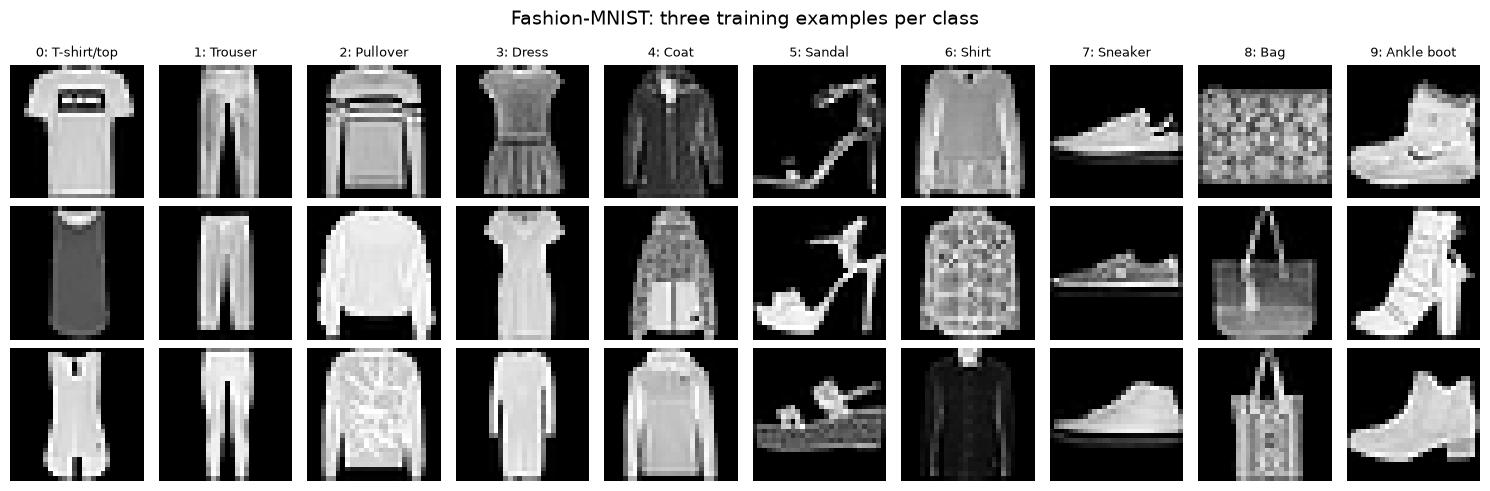

In [3]:
# PROVIDED DATASET GALLERY — three training examples from every Fashion-MNIST class.
examples_per_class = 3
fig, axes = plt.subplots(examples_per_class, 10, figsize=(15, 5))
for class_id, class_name in enumerate(CLASS_NAMES):
    example_ids = np.flatnonzero(y_train == class_id)[:examples_per_class]
    for row, example_id in enumerate(example_ids):
        ax = axes[row, class_id]
        ax.imshow(x_train[example_id, ..., 0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        if row == 0:
            ax.set_title(f"{class_id}: {class_name}", fontsize=9)
fig.suptitle("Fashion-MNIST: three training examples per class", fontsize=14)
fig.tight_layout()
display(fig)
plt.close(fig)


## 0. Train your reference model

Run the provided cell. It trains the CNN for three epochs and saves it locally; later runs load the cached model. Delete `outputs/fashion_mnist_reference_60k.keras` to retrain from scratch.


In [ ]:
def build_model():
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(16, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, name="logits"),
    ], name="fashion_cnn")

def compile_model(model, learning_rate=1e-3):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=["accuracy"])

def train_reference():
    keras.utils.set_random_seed(SEED)
    model = build_model()
    compile_model(model)
    history = model.fit(x_train, y_train, epochs=3, batch_size=256, verbose=2)
    return model, history

started = time.perf_counter()
reference_loaded_from_cache = REFERENCE_CACHE.exists()
if reference_loaded_from_cache:
    reference_model = keras.models.load_model(REFERENCE_CACHE, compile=False)
    reference_history = (json.loads(REFERENCE_HISTORY_CACHE.read_text())
                         if REFERENCE_HISTORY_CACHE.exists() else {})
    print("Loaded your locally cached reference model; training skipped.")
else:
    reference_model, history = train_reference()
    reference_history = history.history
    reference_model.save(REFERENCE_CACHE)
    REFERENCE_HISTORY_CACHE.write_text(json.dumps(reference_history, indent=2))
    print("Trained for 3 epochs and saved your reference model locally.")
reference_training_seconds = time.perf_counter() - started
print(f"Reference setup time: {reference_training_seconds:.1f} seconds")
reference_model.summary()

def predict_labels(model, images):
    return model.predict(images, batch_size=256, verbose=0).argmax(axis=1)

clean_before_pred = predict_labels(reference_model, x_test)
clean_before = float(np.mean(clean_before_pred == y_test))
print(f"Reference clean-evaluation accuracy: {clean_before:.2%}")



### Reference model: clean-evaluation confusion matrix

Rows show true classes; columns show predicted classes for the 9,000 clean-evaluation images. Correct predictions lie on the diagonal.

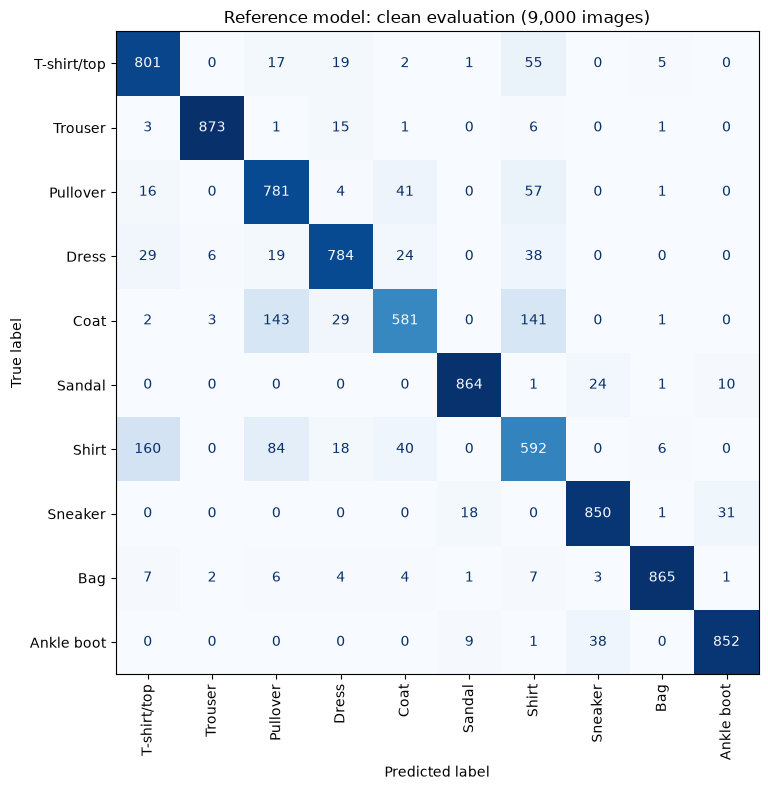

In [5]:
# PROVIDED DISPLAY — evaluate the reference model on the clean-evaluation set.
reference_cm = confusion_matrix(y_test, clean_before_pred, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(reference_cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", xticks_rotation=90, colorbar=False, values_format="d")
ax.set_title(f"Reference model: clean evaluation ({len(y_test):,} images)")
fig.tight_layout()
display(fig)
plt.close(fig)


## 1. PGD evasion attack [50 points]

**Projected Gradient Descent (PGD)** is an iterative evasion attack that uses the model's input gradients to change an image so it is misclassified. After each update, it projects the changes back within a chosen perturbation budget. The model's weights stay fixed; only the input image changes.

[**Adversarial Robustness Toolbox (ART)**](https://github.com/Trusted-AI/adversarial-robustness-toolbox) is a Python library that provides implementations of attacks and defenses. Here, you will wrap your trained Keras model in an ART classifier and use ART's PGD implementation to generate adversarial images. You can experiment with its parameters without implementing PGD yourself.

Try the provided API example, then tune and evaluate your own attack.


### Attack settings

Your goal is to **reduce the reference model's accuracy on the 1,000 attack images** by changing their pixels. Use an **untargeted, white-box attack**: any incorrect class counts as an error, and ART can access the model's input gradients. You may experiment with all PGD parameters, including norm and epsilon. Report your settings and inspect the resulting images; epsilon values are not directly comparable across norms. Keep the reference model and true labels unchanged.

### Measuring attack success: accuracy drop

Evaluate each model on the **same 1,000 images before and after perturbation**, using `y_attack` as the true labels:

**Accuracy drop (percentage points) = 100 × (accuracy on `x_attack` − accuracy on `x_adv`).**

A larger accuracy drop means a more successful attack. For example, 90% original accuracy and 15% attacked accuracy give a 75 percentage-point drop. In Part 2, use the defended model's own original and attacked accuracies. A negative drop means its accuracy is higher on the attacked images.

Accuracy on the 9,000 clean-evaluation images (`x_test`, `y_test`) is checked separately by the provided code. That accuracy is not the baseline for the attack's accuracy-drop calculation.


### Connect your trained model to ART

The estimator below lets ART obtain predictions and input gradients from your reference model. The loss matches the model's logits, and `clip_values=(0,1)` keeps generated pixels in the valid image range.


In [ ]:
# PROVIDED ART ESTIMATOR — expose the trained model's predictions and input gradients.
from art.estimators.classification import TensorFlowV2Classifier
from art.attacks.evasion import ProjectedGradientDescent
import art
print("ART version:", art.__version__)

def wrap_art(model):
    return TensorFlowV2Classifier(model=model, nb_classes=10, input_shape=(28, 28, 1),
        loss_object=tf.keras.losses.CategoricalCrossentropy(from_logits=True),
        clip_values=(0.0, 1.0), channels_first=False)

classifier = wrap_art(reference_model)
def one_hot(labels): return keras.utils.to_categorical(labels, 10).astype("float32")

attack_source_pred = predict_labels(reference_model, x_attack)
print(f"Reference accuracy on original attack images: {np.mean(attack_source_pred == y_attack):.2%}")


### Provided ART API demonstration

#### ART PGD parameters

| Parameter | Meaning |
|---|---|
| `estimator` | Your trained model wrapped as an ART classifier. |
| `norm` | Perturbation measure: `1` for L1, `2` for L2, or `"inf"` for L∞. |
| `eps` | Maximum perturbation size under the chosen norm. |
| `eps_step` | Step size for each attack update. |
| `max_iter` | Number of attack updates. |
| `num_random_init` | Number of random starts; `0` disables random starts. |
| `targeted` | `False` seeks any wrong class; `True` seeks a chosen target class. Use `False` for this assignment. |
| `batch_size` | Number of images processed together. |
| `decay` | Momentum decay factor; `None` disables momentum. |
| `random_eps` | Whether to randomly vary epsilon during generation. |
| `verbose` | Whether to show progress bars. |

Apply PGD to the **same bag image** using L1, L2, and L∞. The top row shows the original and attacked images; the bottom row shows pixel changes (red = increase, blue = decrease). All maps use the same color scale, with colors clipped at ±0.25.

These settings highlight typical patterns: **L1** concentrates changes in a few pixels, **L2** distributes changes with varying strengths, and **L∞** allows changes throughout the image up to a per-pixel limit. Random starts are disabled to make these patterns clearer. The budgets are illustrative and use different scales across norms. This example also shows a prediction flip under L1. Change `demo_index` or the settings to experiment.

[ART PGD documentation](https://adversarial-robustness-toolbox.readthedocs.io/en/latest/modules/attacks/evasion.html#projected-gradient-descent-pgd)


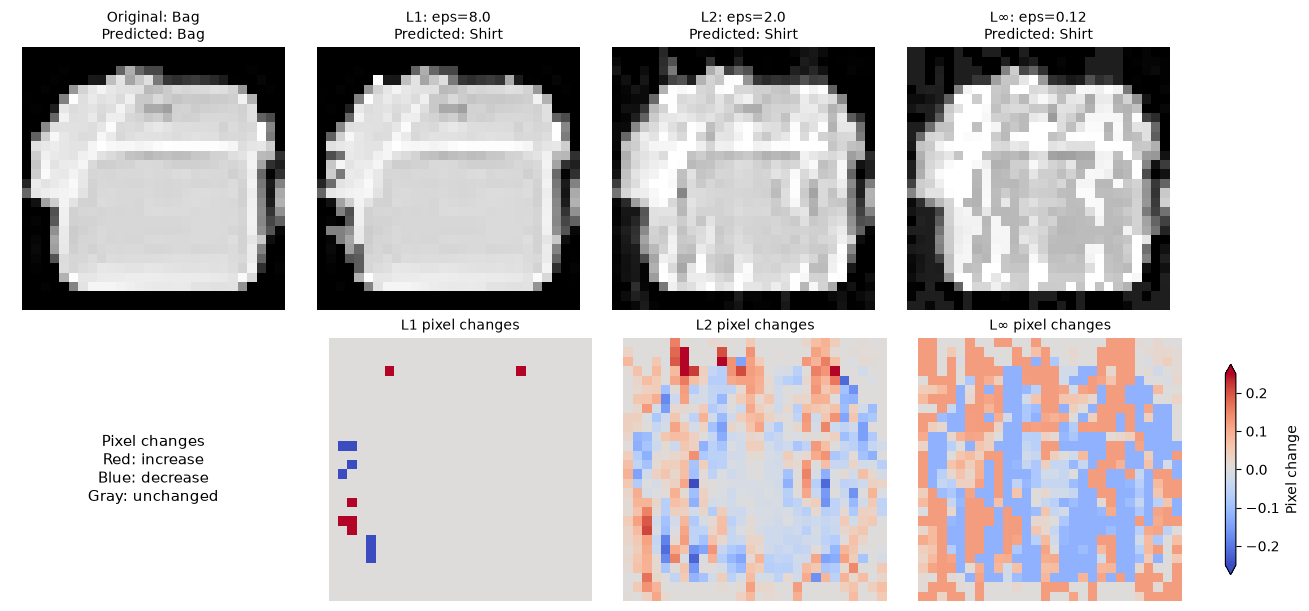

In [7]:
# EDITABLE API DEMO — one image, three norms, with pixel-change maps.
keras.utils.set_random_seed(SEED)
demo_index = 317  # Bag example selected to also demonstrate a sparse L1 prediction flip.
demo_x = x_attack[demo_index:demo_index + 1]
demo_y = y_attack[demo_index:demo_index + 1]
demo_configs = [
    {"norm": 1, "eps": 8.0, "eps_step": 0.5},
    {"norm": 2, "eps": 2.0, "eps_step": 0.15},
    {"norm": "inf", "eps": 0.12, "eps_step": 0.01},
]
common_settings = dict(max_iter=80, num_random_init=0, targeted=False,
                       batch_size=1, decay=None, random_eps=False, verbose=False)

fig, axes = plt.subplots(2, 4, figsize=(13, 6), layout="constrained")
original_pred = predict_labels(reference_model, demo_x)[0]
axes[0,0].imshow(demo_x[0, ..., 0], cmap="gray", vmin=0, vmax=1)
axes[0,0].set_title(f"Original: {CLASS_NAMES[demo_y[0]]}\nPredicted: {CLASS_NAMES[original_pred]}", fontsize=10)
axes[1,0].text(0.5, 0.5, "Pixel changes\nRed: increase\nBlue: decrease\nGray: unchanged",
               ha="center", va="center", fontsize=11)
for column, config in enumerate(demo_configs, start=1):
    demo_pgd = ProjectedGradientDescent(estimator=classifier, **common_settings, **config)
    demo_adv = demo_pgd.generate(x=demo_x.copy(), y=one_hot(demo_y))
    predicted = predict_labels(reference_model, demo_adv)[0]
    norm_name = {1: "L1", 2: "L2", "inf": "L∞"}[config["norm"]]
    axes[0,column].imshow(demo_adv[0, ..., 0], cmap="gray", vmin=0, vmax=1)
    axes[0,column].set_title(f"{norm_name}: eps={config['eps']}\nPredicted: {CLASS_NAMES[predicted]}", fontsize=10)
    # Show pixel differences directly, with a shared color scale for all three norms.
    changes = demo_adv[0, ..., 0] - demo_x[0, ..., 0]
    change_plot = axes[1,column].imshow(changes, cmap="coolwarm", vmin=-0.25, vmax=0.25)
    axes[1,column].set_title(f"{norm_name} pixel changes", fontsize=10)
for ax in axes.flat:
    ax.axis("off")
fig.colorbar(change_plot, ax=list(axes[1,1:]), shrink=0.8,
             label="Pixel change", extend="both")
display(fig)
plt.close(fig)


### 1.1. Generate PGD attacks [30 points]

Use ART's `ProjectedGradientDescent` to attack all **1,000 images** in `x_attack`, using their true labels in `y_attack`. Choose **one configuration** of norm, epsilon, and other PGD parameters and fill in the `attack_config` dictionary below. Use this dictionary as keyword arguments when constructing the attack: `ProjectedGradientDescent(estimator=classifier, **attack_config)`.

Store the generated images in `x_adv`, preserving the source order and labels. Keep pixels as finite float32 values in [0,1]. Your attack should achieve an **accuracy drop of at least 75 percentage points**, measured in Section 1.2.

Keep `x_adv` unchanged: Section 2 will evaluate the defended model on these exact generated images. No file saving or written explanation is required.


In [ ]:
# YOUR WORK — 1.1. Choose the attack parameters, then generate x_adv.
attack_config = {
    "norm": None,             # Choose 1, 2, or "inf".
    "eps": None,              # Perturbation budget (non-negative number).
    "eps_step": None,         # Step size (positive number).
    "max_iter": None,         # Number of updates (positive integer).
    "num_random_init": None,  # Number of random starts (integer >= 0).
    "targeted": False,        # Keep False for this untargeted attack.
    "batch_size": 128,        # Images processed together; you may change this.
    "verbose": False,         # Set True to display progress bars.
}
# You may add other supported PGD parameters, such as decay or random_eps.

# Construct PGD with classifier and attack_config, then generate attacks
# for every image in x_attack using the true labels in y_attack.
x_adv = None


### 1.2. Evaluate the attack [20 points]

Complete `attack_report`, using the existing `attack_config` dictionary. `attack_source_pred` already contains the reference model's predictions on the original `x_attack` images. The provided displays calculate their own predictions for the figures. Run them after completing the report.

| Field | Meaning |
|---|---|
| `attack_config` | The configuration dictionary from Section 1.1. |
| `attack_count` | Number of attack images: `len(y_attack)` (1,000). |
| `attack_source_accuracy` | Accuracy on original `x_attack` images, against `y_attack`. |
| `attacked_accuracy` | Accuracy on `x_adv`, against the same `y_attack` labels. |
| `accuracy_drop_pp` | 100 × (`attack_source_accuracy` − `attacked_accuracy`). |
| `per_class` | Ten rows with the class-level results below. |

| Field in each `per_class` row | Meaning |
|---|---|
| `class` | True class label, from 0 to 9. |
| `count` | Images with this true label (100 per class). |
| `attack_source_accuracy` | Accuracy on the original images of this class. |
| `attacked_accuracy` | Accuracy on the attacked versions of those same images. |
| `accuracy_drop_pp` | 100 × (original accuracy − attacked accuracy) for this class. |

Counts are integers; accuracies are fractions in [0,1]; drops are in percentage points.


In [ ]:
# YOUR WORK — 1.2. Calculate the reference-model metrics and complete the report.
attack_report = {
    "attack_config": attack_config,
    "attack_count": None,
    "attack_source_accuracy": None,
    "attacked_accuracy": None,
    "accuracy_drop_pp": None,
    "per_class": [
        {"class": 0, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 1, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 2, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 3, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 4, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 5, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 6, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 7, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 8, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 9, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
    ],
}


In [ ]:
# PROVIDED DISPLAYS — no metric calculation is hidden in these displays.
def show_attack_report(report):
    print(f"Attack images: {report['attack_count']}")
    print(f"Original accuracy: {report['attack_source_accuracy']:.2%}")
    print(f"Attacked accuracy: {report['attacked_accuracy']:.2%}")
    print(f"Accuracy drop: {report['accuracy_drop_pp']:+.2f} percentage points")
    print("Attack configuration:", report["attack_config"])
    print("Class                N   Original   Attacked    Drop (pp)")
    for row in report["per_class"]:
        print(f"{CLASS_NAMES[row['class']]:16} {row['count']:5} "
              f"{row['attack_source_accuracy']:10.2%} {row['attacked_accuracy']:10.2%} "
              f"{row['accuracy_drop_pp']:+11.2f}")

def plot_confusions(truths, predictions, titles):
    fig, axes = plt.subplots(1, len(predictions), figsize=(8 * len(predictions), 7))
    for ax, truth, pred, title in zip(np.atleast_1d(axes), truths, predictions, titles):
        cm = confusion_matrix(truth, pred, labels=np.arange(10))
        ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
            ax=ax, cmap="Blues", xticks_rotation=90, colorbar=False, values_format="d")
        ax.set_title(title)
    fig.tight_layout()
    display(fig)
    plt.close(fig)

show_attack_report(attack_report)
reference_attack_predictions = predict_labels(reference_model, x_adv)
plot_confusions([y_test, y_attack], [clean_before_pred, reference_attack_predictions],
                ["Reference: clean evaluation (9,000)", "Reference: PGD attacks (1,000)"])
fig, axes = plt.subplots(3, 8, figsize=(14, 6))
for j in range(8):
    axes[0,j].imshow(x_attack[j,...,0], cmap="gray", vmin=0, vmax=1)
    axes[0,j].set_title(f"True: {CLASS_NAMES[y_attack[j]]}", fontsize=8)
    axes[1,j].imshow(x_adv[j,...,0], cmap="gray", vmin=0, vmax=1)
    axes[1,j].set_title(f"Pred: {CLASS_NAMES[reference_attack_predictions[j]]}", fontsize=8)
    axes[2,j].imshow((x_adv-x_attack)[j,...,0], cmap="coolwarm", vmin=-1, vmax=1)
    for i in range(3): axes[i,j].axis("off")
fig.suptitle("Original / PGD / signed perturbation")
fig.tight_layout()
display(fig)
plt.close(fig)


## 2. Adversarial training [50 points]

In Part 1, you reduced the model's accuracy using PGD. The goal now is to **train a model that is less affected by those same attacks**. Generate additional PGD examples from the training set, keep their true labels, and combine them with the original training data to retrain the model.

Then evaluate the defended model on the original attack images and the unchanged `x_adv` from Part 1. Aim for a **smaller accuracy drop**, while maintaining good accuracy on the separate clean-evaluation set.

### 2.1. Build more training data and retrain [30 points]

Generate PGD examples from `x_train`, keeping their `y_train` labels. Combine them with the original training data and train a separate `defended_model`. Keep the evaluation and attack sets out of training.

You may reuse the reference model's architecture and training settings, and the PGD settings from Part 1, or adjust them. Fine-tune a copy of the reference model or train from scratch.

Aim for an attack-set **accuracy drop ≤10 percentage points**, **clean-evaluation accuracy ≥85%**, and a **clean-evaluation accuracy loss of at most 5 percentage points relative to the reference model**.


In [ ]:
# YOUR WORK — 2.1. Build additional training data and train a separate model.
# Use only the training split as augmentation sources; retain the true class labels.
defended_model = None



### 2.2. Evaluate on the same attack dataset [20 points]

Complete `defense_report` using the **defended model**. Use the original `x_attack` and unchanged `x_adv` from Section 1.1, with `y_attack` as the true labels for both. Run the provided displays after completing the report.

| Field | Meaning |
|---|---|
| `attack_config` | The same configuration dictionary used in Part 1. |
| `attack_count` | Number of attack images: `len(y_attack)` (1,000). |
| `attack_source_accuracy` | Defended-model accuracy on original `x_attack` images. |
| `attacked_accuracy` | Defended-model accuracy on the unchanged `x_adv` images. |
| `accuracy_drop_pp` | 100 × (`attack_source_accuracy` − `attacked_accuracy`), using the defended model for both accuracies. |
| `utility_drop_pp` | 100 × (reference accuracy − defended accuracy) on the separate clean-evaluation set (`x_test`, `y_test`). |
| `drop_reduction_pp` | `attack_report["accuracy_drop_pp"]` − `defense_report["accuracy_drop_pp"]`; positive means the defense reduced the attack's effect. |
| `per_class` | Results for each true class, as described below. |

| Field in each `per_class` row | Meaning |
|---|---|
| `class` | True class label, from 0 to 9. |
| `count` | Attack images with this true label (100 per class). |
| `attack_source_accuracy` | Defended-model accuracy on the original images of this class. |
| `attacked_accuracy` | Defended-model accuracy on their attacked versions. |
| `accuracy_drop_pp` | 100 × (original accuracy − attacked accuracy) for this class. |

Counts are integers; accuracies are fractions in [0,1]; drops are in percentage points.


In [ ]:
# YOUR WORK — calculate the defended-model metrics and complete the report.
defense_report = {
    "attack_config": attack_config,
    "attack_count": None,
    "attack_source_accuracy": None,
    "attacked_accuracy": None,
    "accuracy_drop_pp": None,
    "utility_drop_pp": None,
    "drop_reduction_pp": None,
    "per_class": [
        {"class": 0, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 1, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 2, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 3, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 4, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 5, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 6, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 7, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 8, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
        {"class": 9, "count": None, "attack_source_accuracy": None,
         "attacked_accuracy": None, "accuracy_drop_pp": None},
    ],
}


In [ ]:
# PROVIDED DISPLAY — compare calculated accuracies and drops.
print(f"{'Metric':32} {'Reference':>12} {'Defended':>12}")
for label, key in [("Original attack images (1,000)", "attack_source_accuracy"),
                   ("Attacked images (1,000)", "attacked_accuracy")]:
    print(f"{label:32} {attack_report[key]:12.2%} {defense_report[key]:12.2%}")
print(f"{'Attack accuracy drop (pp)':32} {attack_report['accuracy_drop_pp']:+12.2f} {defense_report['accuracy_drop_pp']:+12.2f}")
print(f"Clean utility drop: {defense_report['utility_drop_pp']:+.2f} percentage points")
print(f"Reduction in attack accuracy drop: {defense_report['drop_reduction_pp']:+.2f} percentage points")
# Obtain predictions for the provided clean-evaluation check and confusion matrices.
defended_clean_predictions = predict_labels(defended_model, x_test)
defended_attack_predictions = predict_labels(defended_model, x_adv)
print(f"Separate clean-evaluation check: {np.mean(defended_clean_predictions == y_test):.2%}")
show_attack_report(defense_report)
plot_confusions([y_test, y_attack], [defended_clean_predictions, defended_attack_predictions],
                ["Defended: clean evaluation (9,000)", "Defended: same PGD attacks (1,000)"])


## Before submitting

Complete all four **YOUR WORK** cells. Run the notebook from top to bottom and save it with outputs visible.

Include the API demo images, your selected PGD configuration, Part 1 report and figures, training outputs, and the Part 2 comparison report and confusion matrices. Part 2 must reuse the unchanged `x_adv` from Part 1 and compare it with the same original `x_attack` images.

Submit **only `assignment_2a.ipynb`**. No attack-file saving or written interpretation is required.
